# Malpractice EDA

## set-up

In [143]:
#libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [144]:
#plot formatting
FIGURE_FOLDER = "Figures"

TITLE_SIZE = 16
LABEL_SIZE = 13
TICK_SIZE = 11

LINE_WIDTH = 2
MARKER_SIZE = 6

plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300

plt.rcParams["axes.titlesize"] = TITLE_SIZE
plt.rcParams["axes.labelsize"] = LABEL_SIZE

plt.rcParams["xtick.labelsize"] = TICK_SIZE
plt.rcParams["ytick.labelsize"] = TICK_SIZE

In [211]:
#table formatting
def save_table(df, filename):
    # Create figure sized to the dataframe
    fig, ax = plt.subplots(figsize=(12, len(df) * 0.6 + 1))
    ax.axis("off")

    # Create the table
    tbl = ax.table(
        cellText=df.values,
        rowLabels=df.index,
        colLabels=df.columns,
        cellLoc="center",
        rowLoc="center",
        loc="center"
    )

    # Formatting
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(10)
    tbl.scale(1.2, 1.5)

    # Bold header row
    for (row, col), cell in tbl.get_celld().items():
        if row == 0:
            cell.set_text_props(weight="bold")

    plt.tight_layout()

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close(fig)

In [145]:
#call the dataset
master = pd.read_csv("master_panel.csv")
npdb = pd.read_csv("npdb_analysis.csv")
naic = pd.read_csv("naic_analysis.csv")

In [146]:
#dataset overview
print(npdb.shape)
print(npdb.info())
print(npdb.describe())

(171357, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 171357 entries, 0 to 171356
Data columns (total 18 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   record_id               171357 non-null  int64  
 1   state                   171357 non-null  object 
 2   payment_year            171357 non-null  int64  
 3   malpractice_year        171357 non-null  int64  
 4   payment                 171357 non-null  float64
 5   total_payment           171357 non-null  float64
 6   payment_sequence        171357 non-null  object 
 7   license_field           171357 non-null  int64  
 8   reporting_entity        171357 non-null  int64  
 9   allegation              171357 non-null  float64
 10  outcome                 171357 non-null  float64
 11  state_fund_payment      171357 non-null  int64  
 12  settlement_delay        171357 non-null  int64  
 13  license_label           168606 non-null  object 
 14  allegat

In [147]:
#dataset overview
print(naic.shape)
print(naic.info())
print(naic.describe())

(766, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 766 entries, 0 to 765
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   year                    766 non-null    int64  
 1   state                   766 non-null    object 
 2   reporting_entity_count  766 non-null    int64  
 3   premiums_written        766 non-null    float64
 4   premiums_earned         766 non-null    float64
 5   losses                  766 non-null    float64
 6   defense_costs           766 non-null    float64
 7   loss_ratio              766 non-null    float64
dtypes: float64(5), int64(2), object(1)
memory usage: 48.0+ KB
None
              year  reporting_entity_count  premiums_written  premiums_earned  \
count   766.000000              766.000000      7.660000e+02     7.660000e+02   
mean   2018.007833               94.027415      2.064206e+08     2.043069e+08   
std       4.325929               21.266206    

In [148]:
#dataset overview
print(master.shape)
print(master.info())
print(master.describe())

(766, 61)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 766 entries, 0 to 765
Data columns (total 61 columns):
 #   Column                                               Non-Null Count  Dtype  
---  ------                                               --------------  -----  
 0   state                                                766 non-null    object 
 1   year                                                 766 non-null    int64  
 2   payment_reports                                      766 non-null    int64  
 3   total_payments                                       766 non-null    float64
 4   mean_payment                                         766 non-null    float64
 5   median_payment                                       766 non-null    float64
 6   std_payment                                          766 non-null    float64
 7   max_payment                                          766 non-null    float64
 8   min_payment                                          766 non

In [149]:
npdb.head()

,record_id,state,payment_year,malpractice_year,payment,total_payment,payment_sequence,license_field,reporting_entity,allegation,outcome,state_fund_payment,settlement_delay,license_label,allegation_group,practitioner_group,allegation_group_label,outcome_label
0,1053560,NY,2011,2005,295000.0,295000.0,S,10,500,112.0,4.0,0,6,Allopathic Physician (MD),10.0,Physician,Anesthesia Related,Major Temporary Injury
1,1053561,WA,2011,2009,1550000.0,1550000.0,S,10,500,300.0,9.0,0,2,Allopathic Physician (MD),60.0,Physician,Treatment Related,Death
2,1053563,CA,2011,2008,47500.0,47500.0,S,10,500,101.0,9.0,0,3,Allopathic Physician (MD),1.0,Physician,Diagnosis Related,Death
3,1053565,PA,2011,2006,145000.0,145000.0,S,10,500,305.0,9.0,0,5,Allopathic Physician (MD),60.0,Physician,Treatment Related,Death
4,1053573,AZ,2011,2006,195000.0,195000.0,S,30,500,320.0,5.0,0,5,Dentist,20.0,Dentistry,Surgery Related,Minor Permanent Injury


In [150]:
naic.head()

,year,state,reporting_entity_count,premiums_written,premiums_earned,losses,defense_costs,loss_ratio
0,2011,AK,55,22703036.0,22569754.0,5283794.0,4437422.0,43.07
1,2011,AL,84,140232428.0,134383782.0,15075394.0,34287173.0,36.73
2,2011,AR,73,70104220.0,70565645.0,24739907.0,9220268.0,48.13
3,2011,AZ,96,238798321.0,243554374.0,42444063.0,27266351.0,28.62
4,2011,CA,110,813965769.0,813171873.0,270666539.0,206673899.0,58.70


In [151]:
master.head()

,state,year,payment_reports,total_payments,mean_payment,median_payment,std_payment,max_payment,min_payment,mean_settlement_delay,...,poverty_numerator,education_denominator,bachelors,masters,professional,doctorate,state_fips,poverty_rate,bachelors_or_higher,education_rate
0,AK,2011,17,6405000.0,376764.705882,155000.0,711466.226308,2850000.0,22500.0,3.294118,...,73905.0,456862.0,77153.0,29269.0,8000.0,6039.0,2.0,10.455394,120461.0,26.367043
1,AK,2012,18,6932500.0,385138.888889,185000.0,585743.288620,2450000.0,2500.0,3.833333,...,72400.0,464594.0,79559.0,36321.0,8545.0,5699.0,2.0,10.117271,130124.0,28.008110
2,AK,2013,15,4085250.0,272350.000000,245000.0,267771.787829,995000.0,4500.0,4.066667,...,67016.0,462659.0,84038.0,32966.0,7246.0,5163.0,2.0,9.329040,129413.0,27.971573
3,AK,2014,22,7075000.0,321590.909091,185000.0,460646.734452,1650000.0,8750.0,4.272727,...,80627.0,465149.0,85634.0,33103.0,7223.0,4304.0,2.0,11.233721,130264.0,28.004790
4,AK,2015,19,7552500.0,397500.000000,125000.0,505728.297716,1950000.0,17500.0,3.684211,...,74532.0,469523.0,87869.0,36260.0,10814.0,4473.0,2.0,10.340680,139416.0,29.693114


In [152]:
#missing values due to lack of 2020 and 2025 socioeconomic data
master.isna().sum()

state                    0
year                     0
payment_reports          0
total_payments           0
mean_payment             0
                      ... 
doctorate              102
state_fips             102
poverty_rate           102
bachelors_or_higher    102
education_rate         102
Length: 61, dtype: int64

## National Practitioner Data Bank (NPDB)

The National Practitioner Data Bank (NPDB) contains malpractice payment reports submitted on behalf of healthcare practitioners throughout the United States. This section summarizes the distribution of malpractice payments, practitioner characteristics, allegation types, injury outcomes, and temporal trends observed between 2011 and 2025.

### Summary Statistics

In [216]:
financial_summary = (
    npdb[
        [
            "payment",
            "settlement_delay"
        ]
    ]
    .describe()
    .round(2)
)

financial_summary.rename(
    columns={
        "payment":"Payment Amount (USD)",
        "settlement_delay":"Settlement Delay (Years)"
    },
    inplace=True
)
save_table(
    financial_summary,
    "Figures/NPDB_Summary_Statistics.png"
)


financial_summary


,Payment Amount (USD),Settlement Delay (Years)
count,171357.00,171357.00
mean,355495.67,4.75
std,671738.77,3.03
min,50.00,0.00
25%,57500.00,3.00
50%,185000.00,4.00
75%,485000.00,6.00
max,37500000.00,107.00


Table 1 summarizes the distributions of malpractice payment amounts and settlement delays recorded within the National Practitioner Data Bank. Malpractice payments exhibit substantial variability, with the mean payment exceeding the median payment, indicating a positively skewed distribution driven by relatively few high-value claims. Settlement delays average approximately five years, although most claims are resolved within a considerably shorter period.

In [200]:
#table 3
allegation_table = (
    npdb["allegation_group_label"]
        .value_counts()
        .rename_axis("Allegation")
        .reset_index(name="Reports")
)

allegation_table["Percent"] = (
    allegation_table["Reports"]
    / allegation_table["Reports"].sum()
    *100
).round(2)
plt.savefig(
    f"{FIGURE_FOLDER}/NPDB_Allegation_Distribution.png",
    bbox_inches="tight"
)
allegation_table

,Allegation,Reports,Percent
0,Treatment Related,48570,28.34
1,Diagnosis Related,45113,26.33
2,Surgery Related,41096,23.98
3,Obstetrics Related,9523,5.56
4,Medication Related,8857,5.17
5,Monitoring Related,6380,3.72
6,Other Miscellaneous,4755,2.77
7,Anesthesia Related,4384,2.56
8,Equipment/Product Related,1226,0.72
9,Behavioral Health Related,1087,0.63


<Figure size 768x576 with 0 Axes>

Table 2 summarizes malpractice payment reports by allegation category. Treatment, diagnosis, and surgery-related allegations collectively account for the majority of malpractice payment reports, whereas all remaining allegation categories contribute substantially fewer observations.

### Reports

In [157]:
annual_reports = (
    npdb
        .groupby("payment_year")
        .size()
)

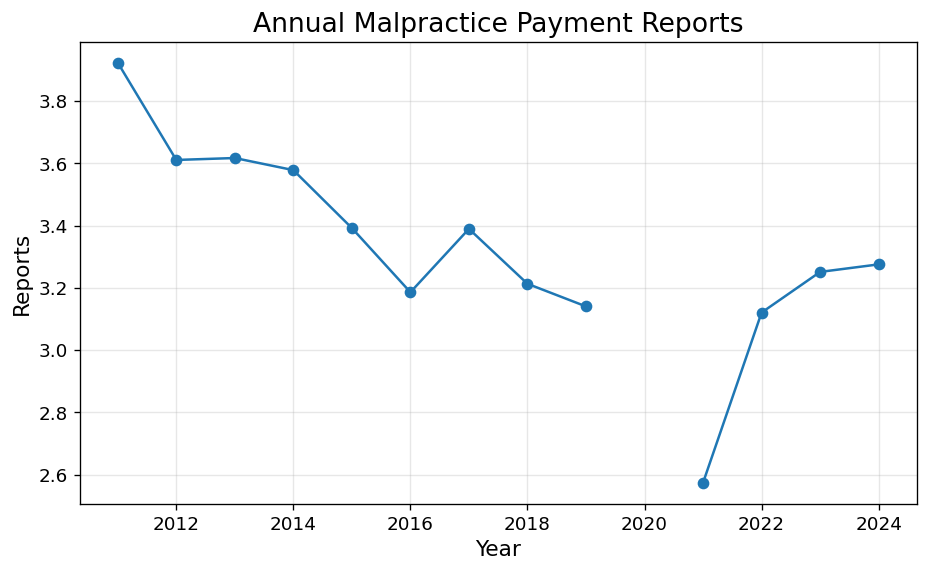

In [201]:
#Figure 1
plt.figure(figsize=(9,5))

plt.plot(
    annual_reports.index,
    annual_reports.values,
    marker="o"
)

plt.title("Annual Malpractice Payment Reports")
plt.xlabel("Year")
plt.ylabel("Reports")

plt.grid(alpha=0.3)

plt.savefig(
    f"{FIGURE_FOLDER}/NPDB_Annual_Reports.png",
    bbox_inches="tight"
)
plt.show()

Figure 1 illustrates annual malpractice payment reports between 2011 and 2025. Report counts remain relatively stable throughout most of the study period before declining noticeably during 2020 and 2021. Beginning in 2022, report counts increase toward pre-2020 levels, suggesting a temporary interruption rather than a sustained long-term decline.

In [160]:
annual_payments = (
    npdb
        .groupby("payment_year")["payment"]
        .sum()
)

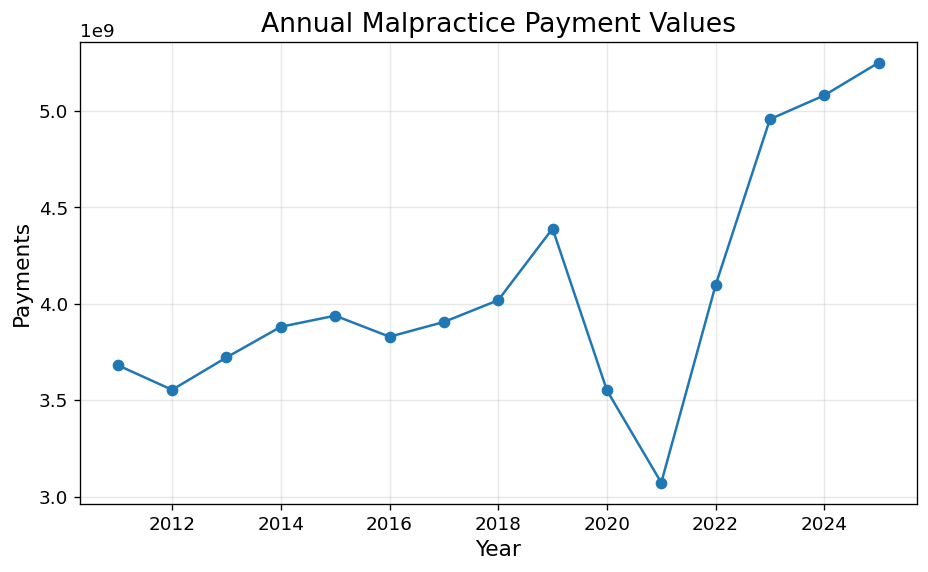

In [202]:
#Figure 2
plt.figure(figsize=(9,5))

plt.plot(
    annual_payments.index,
    annual_payments.values,
    marker="o"
)

plt.title("Annual Malpractice Payment Values")
plt.xlabel("Year")
plt.ylabel("Payments")

plt.grid(alpha=0.3)
plt.savefig(
    f"{FIGURE_FOLDER}/NPDB_Annual_Payment_Values.png",
    bbox_inches="tight"
)
plt.show()

Figure 2 summarizes the total annual value of malpractice payments reported to the NPDB. Although payment totals fluctuate throughout the study period, the financial magnitude of malpractice payments generally increases over time following the decline observed during 2020 and 2021. The greater variability observed in payment values relative to report counts suggests that changes in payment magnitude contribute substantially to annual financial burden.

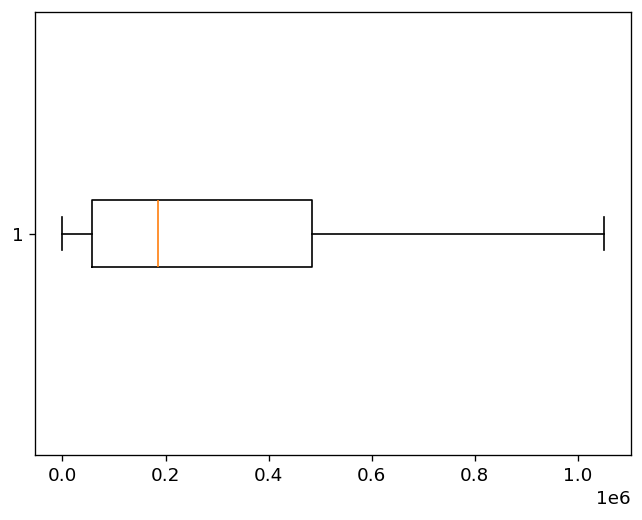

In [203]:
#figure 3
plt.boxplot(
    npdb["payment"],
    vert=False,
    showfliers=False
)
plt.savefig(
    f"{FIGURE_FOLDER}/NPDB_Payment_Boxplot.png",
    bbox_inches="tight"
)

Figure 3 illustrates the distribution of individual malpractice payment amounts. The distribution is strongly right-skewed, with the median substantially lower than the upper quartile and a long upper tail. This pattern indicates that relatively few high-value malpractice payments account for a disproportionate share of total payment dollars.

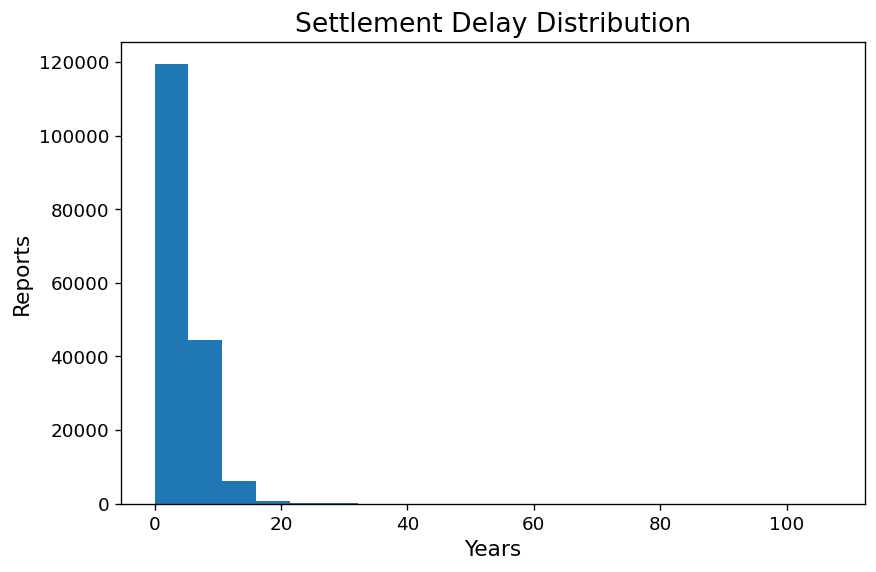

In [204]:
#figure 5
plt.figure(figsize=(8,5))

plt.hist(
    npdb["settlement_delay"],
    bins=20
)

plt.title("Settlement Delay Distribution")

plt.xlabel("Years")

plt.ylabel("Reports")
plt.savefig(
    f"{FIGURE_FOLDER}/NPDB_Settlement_Delay.png",
    bbox_inches="tight"
)
plt.show()

Figure 4 illustrates the distribution of settlement delays between the occurrence of a malpractice event and the associated payment report. Most malpractice payments occur within several years of the original event, although a relatively small number of cases remain unresolved for substantially longer periods, producing a positively skewed distribution.

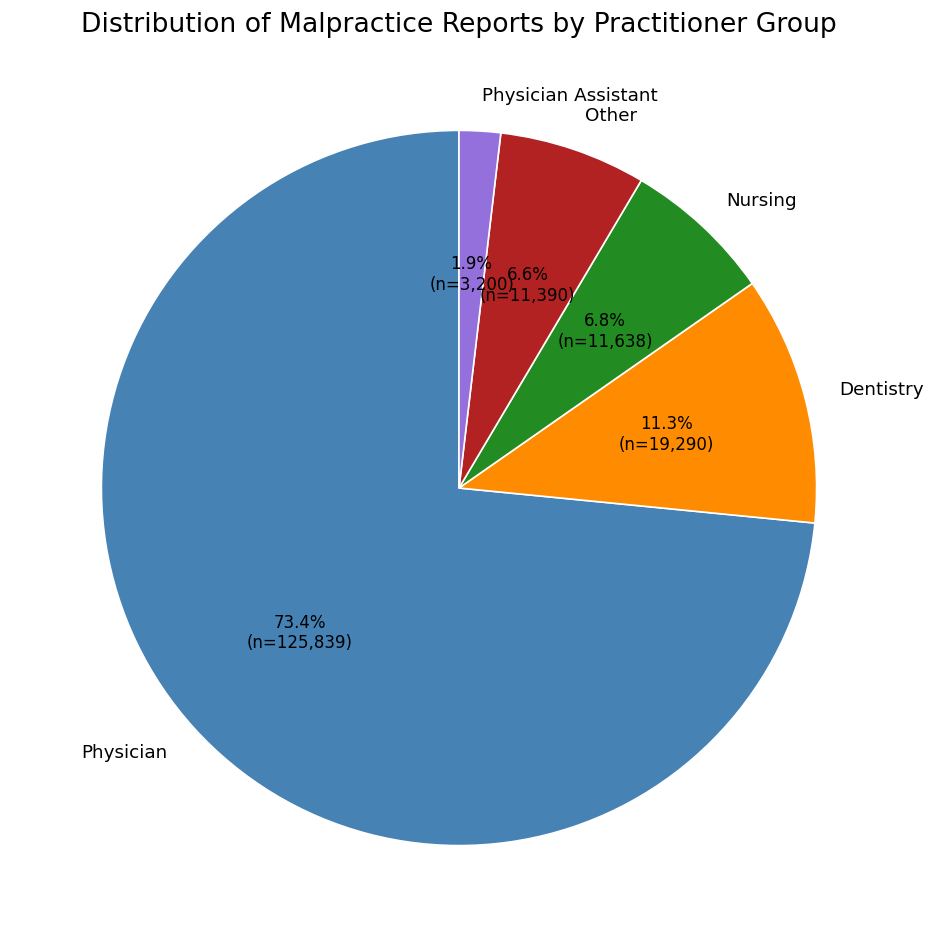

In [205]:
#figure 5
# Practitioner group distribution

practitioner_counts = (
    npdb["practitioner_group"]
        .value_counts()
)

plt.figure(figsize=(8,8))

colors = [
    "steelblue",
    "darkorange",
    "forestgreen",
    "firebrick",
    "mediumpurple"
]

def autopct_format(values):
    def my_format(pct):
        total = sum(values)
        count = int(round(pct * total / 100.0))
        return f"{pct:.1f}%\n(n={count:,})"
    return my_format

plt.pie(
    practitioner_counts.values,
    labels=practitioner_counts.index,
    autopct=autopct_format(practitioner_counts.values),
    startangle=90,
    colors=colors,
    wedgeprops={"edgecolor": "white"}
)
plt.title("Distribution of Malpractice Reports by Practitioner Group")

plt.tight_layout()
plt.savefig(
    f"{FIGURE_FOLDER}/NPDB_Practitioner_Distribution.png",
    bbox_inches="tight"
)
plt.show()

Figure 5 illustrates the proportion of malpractice payment reports attributed to each practitioner group. Physicians account for the majority of malpractice payment reports, substantially exceeding all remaining practitioner categories. This reflects the dominant contribution of physician-related claims within the NPDB malpractice payment records.

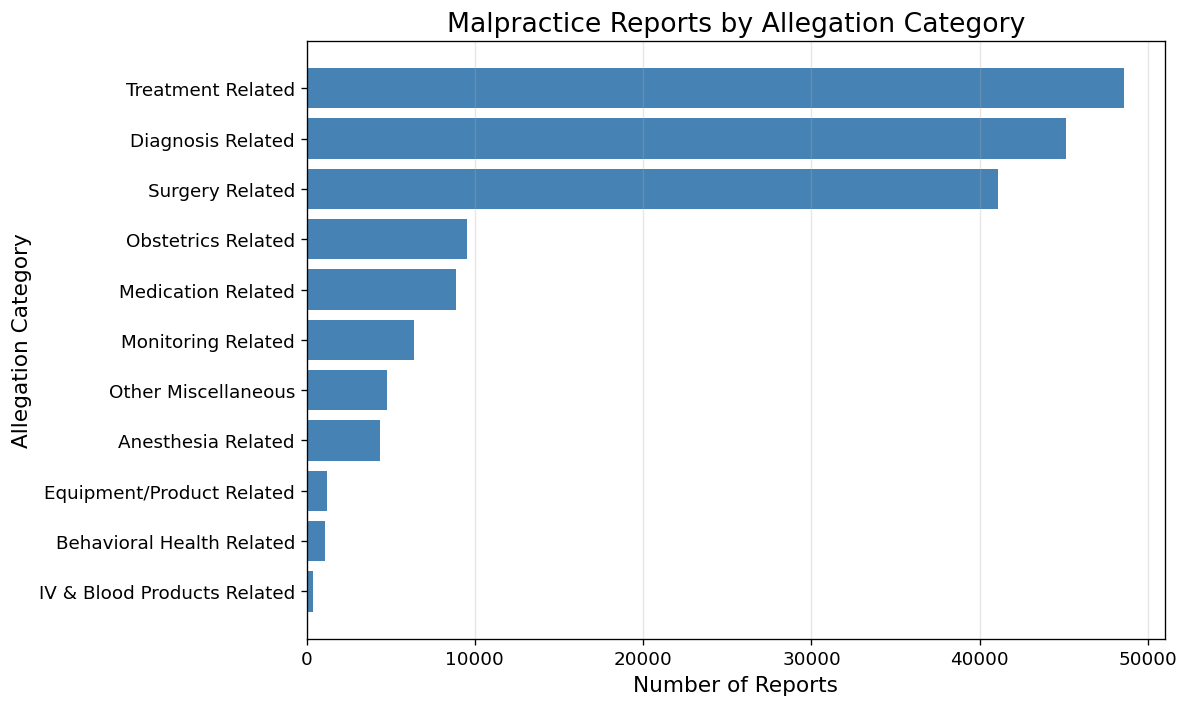

In [206]:
#figure 6
# Allegation distribution

allegation_counts = (
    npdb["allegation_group_label"]
        .value_counts()
        .sort_values()
)

plt.figure(figsize=(10,6))

plt.barh(
    allegation_counts.index,
    allegation_counts.values,
    color="steelblue"
)

plt.title("Malpractice Reports by Allegation Category")

plt.xlabel("Number of Reports")
plt.ylabel("Allegation Category")

plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(
    f"{FIGURE_FOLDER}/NPDB_Allegation_Distribution.png",
    bbox_inches="tight"
)
plt.show()

Figure 6 compares malpractice payment reports across allegation categories. Treatment-, diagnosis-, and surgery-related allegations account for the majority of malpractice payment reports, whereas all remaining allegation categories occur considerably less frequently throughout the study period.

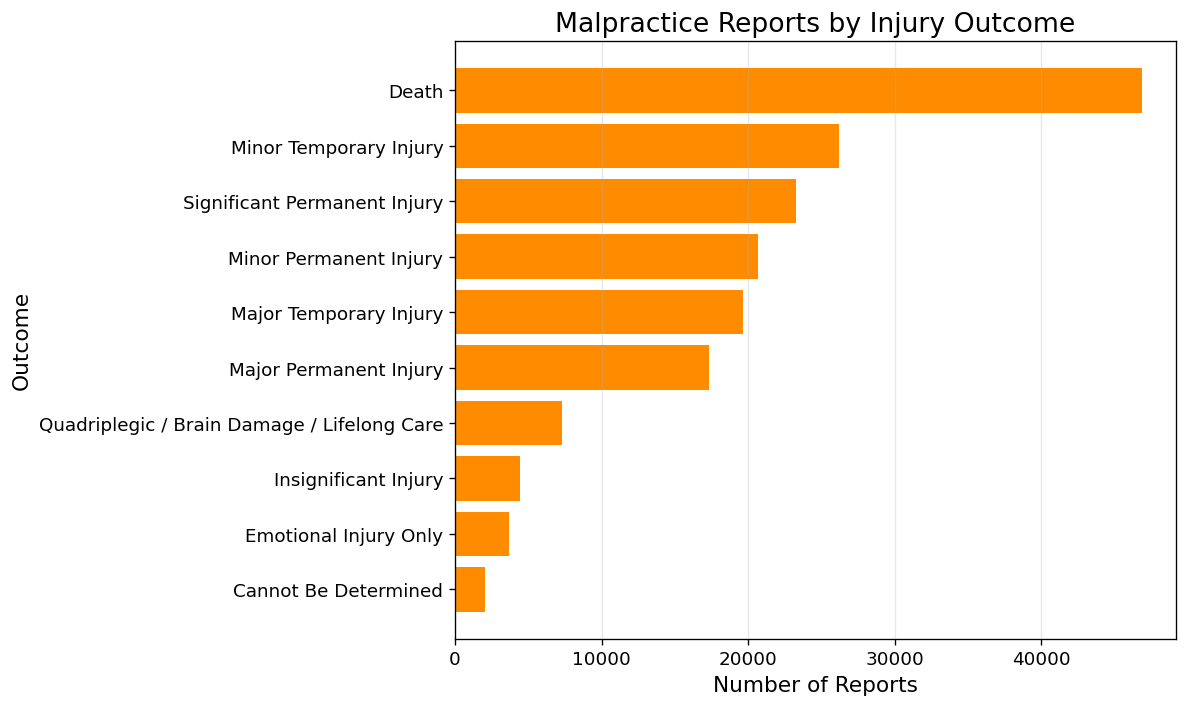

In [207]:
#figure 7
# Outcome distribution

outcome_counts = (
    npdb["outcome_label"]
        .value_counts()
        .sort_values()
)

plt.figure(figsize=(10,6))

plt.barh(
    outcome_counts.index,
    outcome_counts.values,
    color="darkorange"
)

plt.title("Malpractice Reports by Injury Outcome")

plt.xlabel("Number of Reports")
plt.ylabel("Outcome")

plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(
    f"{FIGURE_FOLDER}/NPDB_Outcome_Distribution.png",
    bbox_inches="tight"
)
plt.show()

Figure 7 summarizes the distribution of reported injury outcomes associated with malpractice payment reports. Death represents the most frequently reported outcome, followed by temporary and permanent injury categories. Catastrophic injury outcomes occur relatively infrequently but represent the most severe reported patient outcomes.

### Summary of NPDB Findings

The NPDB data indicate that malpractice payment reporting remained relatively stable throughout much of the study period, with a temporary decline during 2020 and 2021 followed by recovery in subsequent years. Malpractice payment amounts exhibit a strongly right-skewed distribution, indicating that a relatively small number of high-value payments account for a disproportionate share of total malpractice expenditures. Physicians account for the majority of malpractice payment reports, while treatment-, diagnosis-, and surgery-related allegations comprise the most frequently reported malpractice categories. Collectively, these findings establish the primary characteristics of malpractice payment activity and provide the foundation for the subsequent examination of insurer financial trends within the NAIC data.

# National Association of Insurance Commissioners (NAIC)

The National Association of Insurance Commissioners (NAIC) Countrywide Summary of Medical Professional Liability Insurance provides annual state-level measures of insurer financial activity related to medical malpractice insurance. These data include premiums, incurred losses, defense costs, and loss ratios, providing financial context for the malpractice payment trends observed in the NPDB.

## Summary Statistics

In [217]:
naic_summary = (
    naic[
        [
            "premiums_written",
            "premiums_earned",
            "losses",
            "defense_costs",
            "loss_ratio"
        ]
    ]
    .describe()
    .round(2)
)

naic_summary.rename(
    columns={
        "premiums_written":"Premiums Written (USD)",
        "premiums_earned":"Premiums Earned (USD)",
        "losses":"Incurred Losses (USD)",
        "defense_costs":"Defense Costs (USD)",
        "loss_ratio":"Loss Ratio (%)"
    },
    inplace=True
)
save_table(
    naic_summary,
    "Figures/NAIC_Summary_Statistics.png"
)
naic_summary

,Premiums Written (USD),Premiums Earned (USD),Incurred Losses (USD),Defense Costs (USD),Loss Ratio (%)
count,7.660000e+02,7.660000e+02,7.660000e+02,7.660000e+02,766.00
mean,2.064206e+08,2.043069e+08,1.003796e+08,4.162705e+07,66.14
std,2.874998e+08,2.845124e+08,1.667407e+08,6.252534e+07,32.92
min,9.424312e+06,9.076775e+06,-2.945422e+07,-3.338719e+06,-347.42
25%,4.765260e+07,4.686143e+07,1.801802e+07,8.288840e+06,47.55
50%,1.019196e+08,1.015279e+08,4.512629e+07,2.210897e+07,64.91
75%,2.342747e+08,2.328036e+08,1.029891e+08,4.346731e+07,81.28
max,1.791273e+09,1.795873e+09,1.216479e+09,4.417389e+08,228.48


Table 3 summarizes annual insurer financial measures reported by the National Association of Insurance Commissioners. Premiums, incurred losses, defense costs, and loss ratios exhibit substantial variability across states and years, reflecting differences in market size, insurer experience, and malpractice claim activity throughout the study period.

## Reports

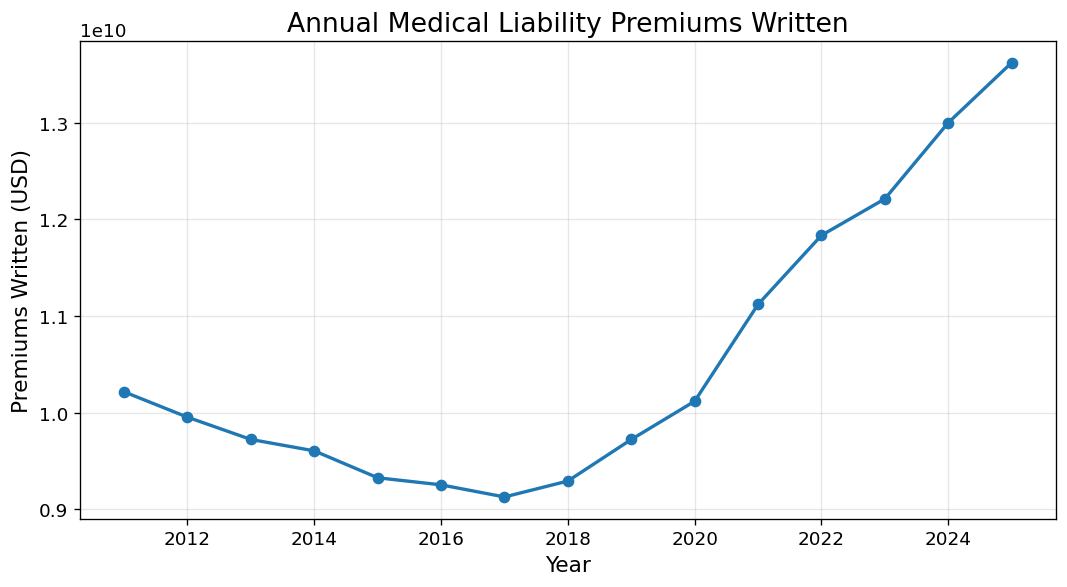

In [175]:
#figure 9

annual_written = (
    naic
    .groupby("year")["premiums_written"]
    .sum()
)

plt.figure(figsize=(9,5))

plt.plot(
    annual_written.index,
    annual_written.values,
    marker="o",
    linewidth=2
)

plt.title("Annual Medical Liability Premiums Written")
plt.xlabel("Year")
plt.ylabel("Premiums Written (USD)")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{FIGURE_FOLDER}/NAIC_Premiums_Written.png",
    bbox_inches="tight"
)

plt.show()

Figure 9 illustrates annual medical professional liability insurance premiums written between 2011 and 2025. Premium volumes generally increase throughout the study period, indicating growth in the overall size of the medical liability insurance market.

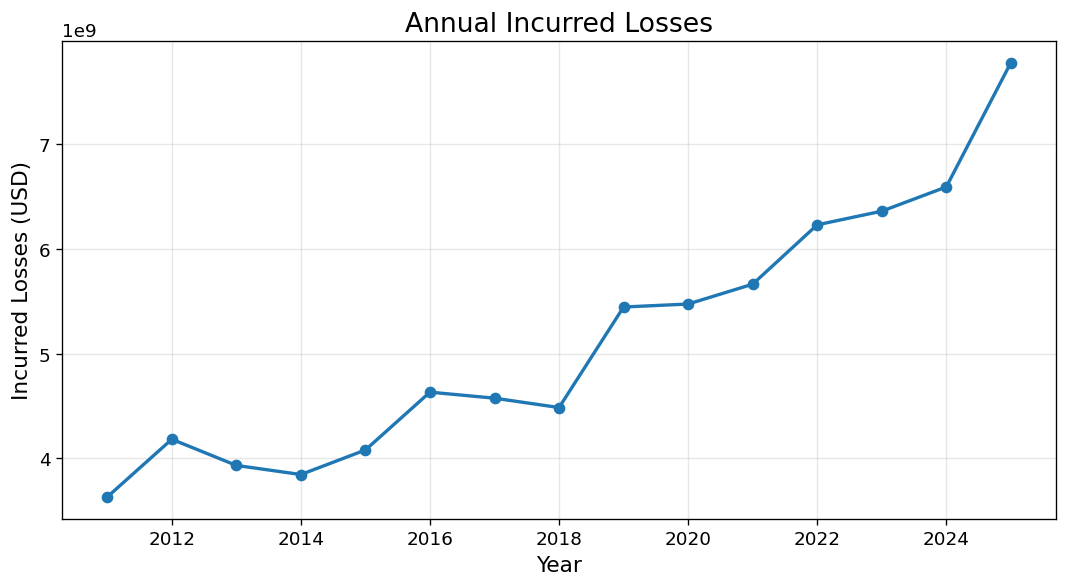

In [176]:
# Figure 11
annual_losses = (
    naic
    .groupby("year")["losses"]
    .sum()
)

plt.figure(figsize=(9,5))

plt.plot(
    annual_losses.index,
    annual_losses.values,
    marker="o",
    linewidth=2
)

plt.title("Annual Incurred Losses")
plt.xlabel("Year")
plt.ylabel("Incurred Losses (USD)")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{FIGURE_FOLDER}/NAIC_Incurred_Losses.png",
    bbox_inches="tight"
)

plt.show()

Figure 11 illustrates annual incurred losses reported by medical professional liability insurers. Incurred losses fluctuate substantially across years, indicating variation in claim payments, reserve adjustments, and insurer loss experience throughout the study period.

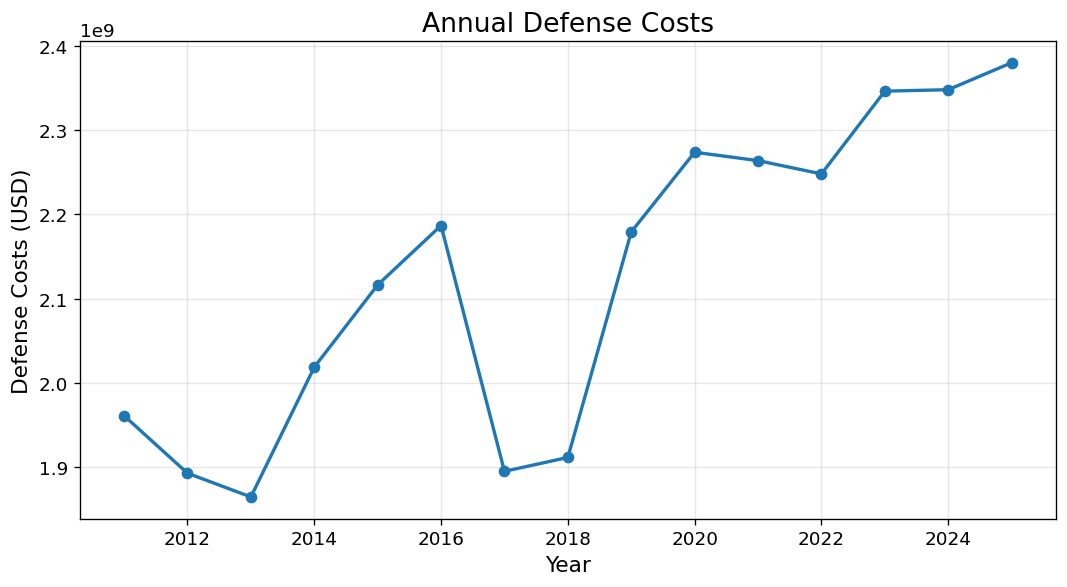

In [177]:
# Figure 12
annual_defense = (
    naic
    .groupby("year")["defense_costs"]
    .sum()
)

plt.figure(figsize=(9,5))

plt.plot(
    annual_defense.index,
    annual_defense.values,
    marker="o",
    linewidth=2
)

plt.title("Annual Defense Costs")
plt.xlabel("Year")
plt.ylabel("Defense Costs (USD, millions)")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{FIGURE_FOLDER}/NAIC_Defense_Costs.png",
    bbox_inches="tight"
)

plt.show()

Figure 11 illustrates annual defense costs incurred by medical professional liability insurers. Defense expenditures generally increase over time, although year-to-year variability is evident throughout the study period.

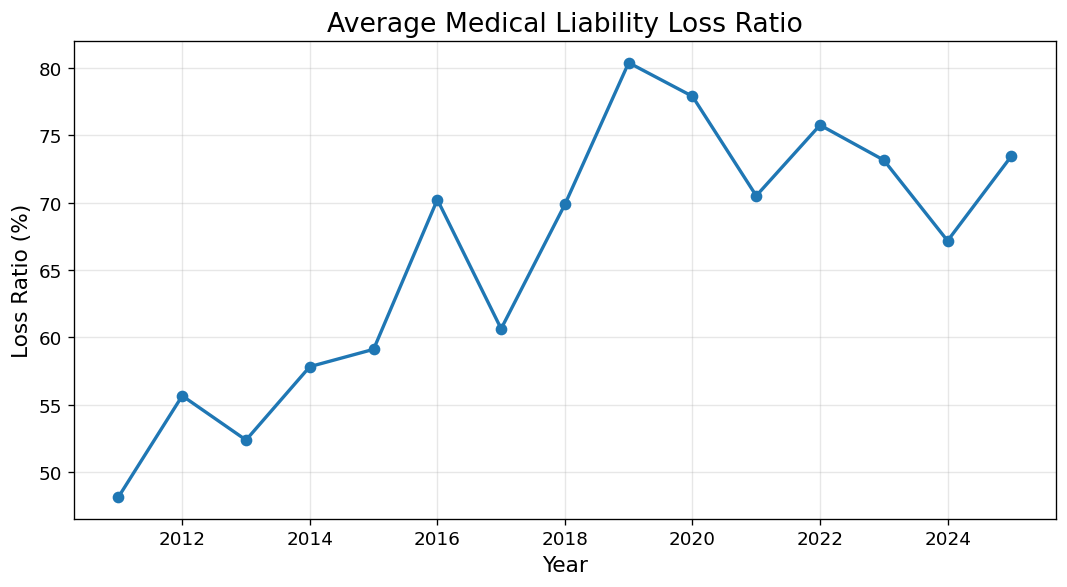

In [178]:
# Figure 12
annual_ratio = (
    naic
    .groupby("year")["loss_ratio"]
    .mean()
)

plt.figure(figsize=(9,5))

plt.plot(
    annual_ratio.index,
    annual_ratio.values,
    marker="o",
    linewidth=2
)

plt.title("Average Medical Liability Loss Ratio")
plt.xlabel("Year")
plt.ylabel("Loss Ratio (%)")

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Figure 12 presents annual defense costs incurred by medical professional liability insurers. Defense expenditures generally increase over time, suggesting that litigation and claim management costs have become a progressively larger component of malpractice-related expenditures.

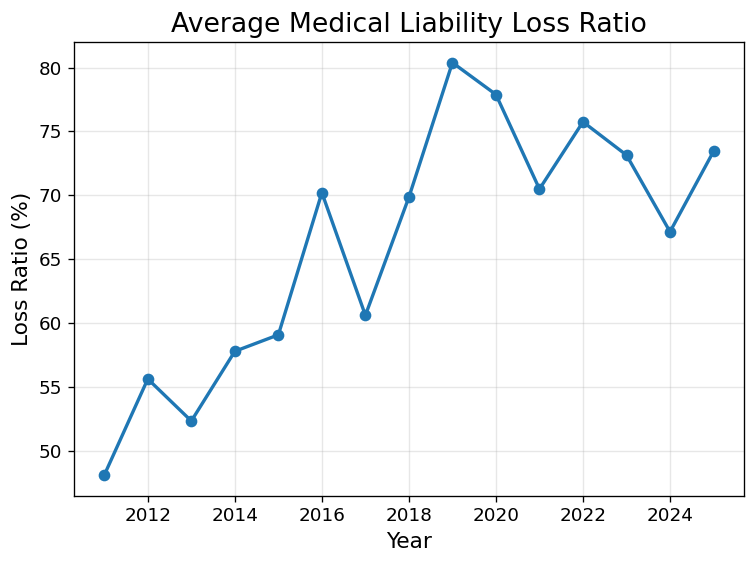

In [179]:
plt.plot(
    annual_ratio.index,
    annual_ratio.values,
    marker="o",
    linewidth=2
)

plt.title("Average Medical Liability Loss Ratio")
plt.xlabel("Year")
plt.ylabel("Loss Ratio (%)")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{FIGURE_FOLDER}/NAIC_Loss_Ratio.png",
    bbox_inches="tight"
)

plt.show()

Figure 13 illustrates the average medical professional liability loss ratio across state-year observations. The loss ratio varies over time, reflecting changes in the balance between insurer losses and earned premiums as market conditions evolve.

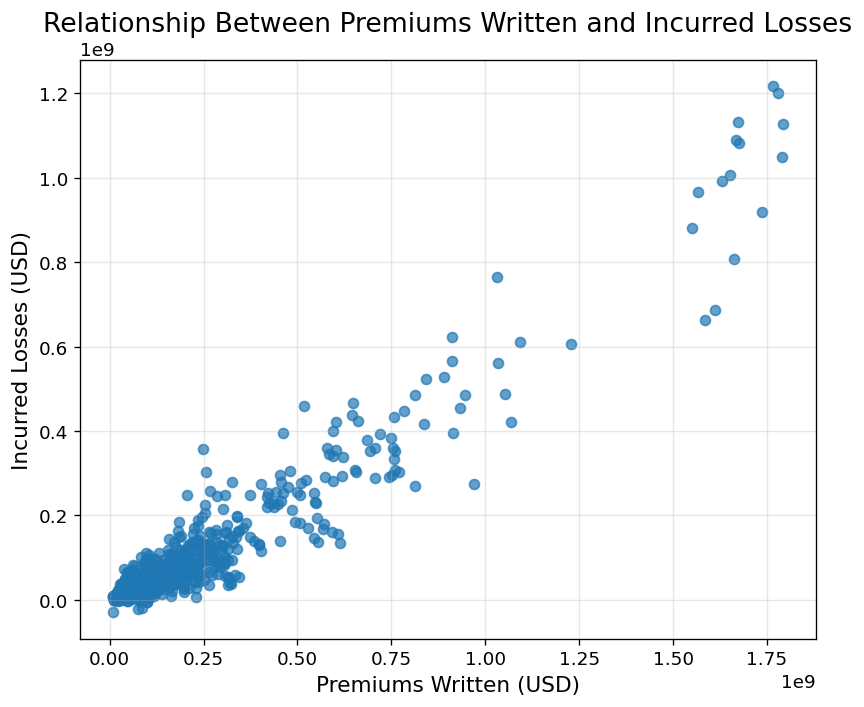

In [180]:
# Figure 14
plt.figure(figsize=(7,6))

plt.scatter(
    naic["premiums_written"],
    naic["losses"],
    alpha=0.7
)

plt.title("Relationship Between Premiums Written and Incurred Losses")
plt.xlabel("Premiums Written (USD)")
plt.ylabel("Incurred Losses (USD)")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{FIGURE_FOLDER}/NAIC_Premiums_vs_Losses.png",
    bbox_inches="tight"
)

plt.show()

Figure 13 ranks the states withFigure 14 illustrates the relationship between premiums written and incurred losses across all state-year observations. A positive association is evident, with larger medical liability insurance markets generally corresponding to greater incurred losses. Although substantial variability exists among observations, the overall pattern suggests that insurer losses tend to increase as premium volume increases. the largest cumulative medical professional liability insurance premiums written during the study period. Larger states generally report higher premium volumes, reflecting differences in market size and insurer activity.

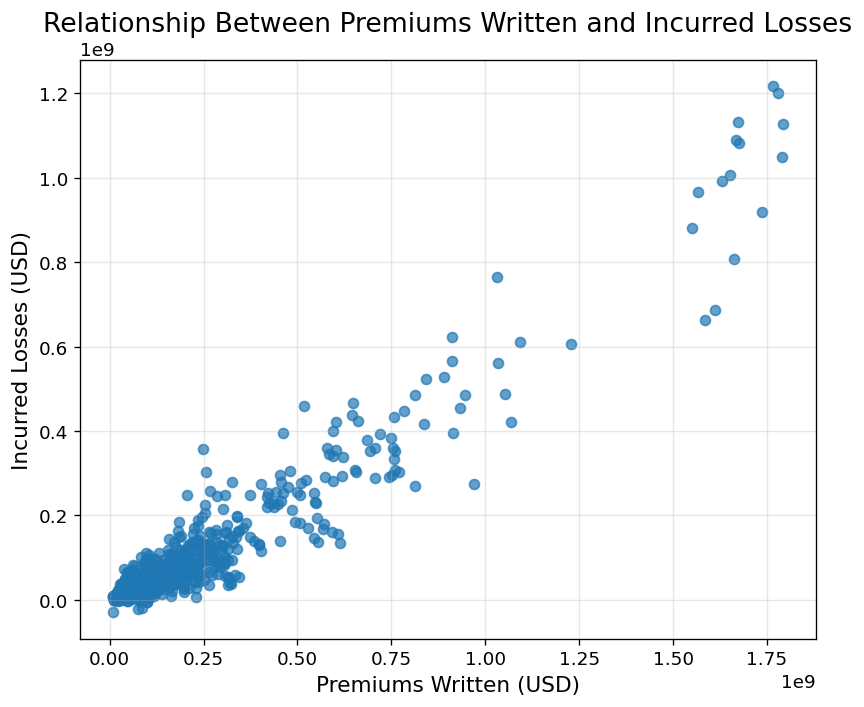

In [181]:
# Figure 16
plt.figure(figsize=(7,6))

plt.scatter(
    naic["premiums_written"],
    naic["losses"],
    alpha=0.7
)

plt.title("Relationship Between Premiums Written and Incurred Losses")
plt.xlabel("Premiums Written (USD)")
plt.ylabel("Incurred Losses (USD)")

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Figure 16 illustrates the relationship between medical professional liability insurance premiums written and incurred losses across all state-year observations. A positive association is evident, with state-year observations reporting higher premium volumes generally corresponding to higher incurred losses. Although considerable variability exists among observations, the overall pattern suggests that larger medical liability insurance markets tend to experience greater insurer losses.

## Summary of Findings

The NAIC data indicate that medical professional liability insurance premiums, incurred losses, and defense costs generally increased throughout the study period, although considerable year-to-year variability is evident. Premiums written and premiums earned exhibit similar long-term upward trends, while incurred losses and loss ratios fluctuate more substantially, reflecting variation in insurer claim experience and reserve adjustments. Collectively, these financial measures provide important context for interpreting malpractice payment trends observed within the National Practitioner Data Bank and establish the insurer-side financial environment examined in the merged analyses.

# Master Data

The merged dataset integrates malpractice payment information from the National Practitioner Data Bank (NPDB), insurer financial measures from the National Association of Insurance Commissioners (NAIC), state-level socioeconomic characteristics from the American Community Survey (ACS), and annual population estimates from the Census Population Estimates Program (PEP). This integrated dataset serves as the primary analytical dataset for evaluating relationships between malpractice activity, insurer financial performance, and socioeconomic conditions.

## Summary Statistics

In [218]:
master_summary = (
    master[
        [
            "payment_reports",
            "payment_reports_per_100k",
            "total_payments",
            "payment_dollars_per_capita",
            "premiums_written",
            "losses",
            "defense_costs",
            "median_household_income",
            "poverty_rate",
            "education_rate"
        ]
    ]
    .describe()
    .round(2)
)

master_summary.rename(
    columns={
        "payment_reports":"Payment Reports",
        "payment_reports_per_100k":"Reports per 100,000",
        "total_payments":"Total Payments (USD)",
        "payment_dollars_per_capita":"Payments per Capita (USD)",
        "premiums_written":"Premiums Written (USD)",
        "losses":"Incurred Losses (USD)",
        "defense_costs":"Defense Costs (USD)",
        "median_household_income":"Median Household Income (USD)",
        "poverty_rate":"Poverty Rate (%)",
        "education_rate":"Bachelor's Degree or Higher (%)"
    },
    inplace=True
)
save_table(
    master_summary,
    "Figures/Master_Summary_Statistics.png"
)
master_summary

,Payment Reports,"Reports per 100,000",Total Payments (USD),Payments per Capita (USD),Premiums Written (USD),Incurred Losses (USD),Defense Costs (USD),Median Household Income (USD),Poverty Rate (%),Bachelor's Degree or Higher (%)
count,766.00,664.00,7.660000e+02,664.00,7.660000e+02,7.660000e+02,7.660000e+02,664.00,664.00,664.00
mean,223.94,3.33,7.959813e+07,12.24,2.064206e+08,1.003796e+08,4.162705e+07,62749.46,13.52,32.03
std,312.34,1.68,1.163357e+08,8.33,2.874998e+08,1.667407e+08,6.252534e+07,14324.83,3.16,6.89
min,5.00,0.64,6.753000e+05,0.89,9.424312e+06,-2.945422e+07,-3.338719e+06,36919.00,7.19,18.47
25%,51.25,2.14,1.868412e+07,6.86,4.765260e+07,1.801802e+07,8.288840e+06,51485.75,11.07,27.36
50%,124.00,2.98,3.948292e+07,9.48,1.019196e+08,4.512629e+07,2.210897e+07,60679.00,13.00,31.16
75%,228.75,4.04,7.844091e+07,15.32,2.342747e+08,1.029891e+08,4.346731e+07,71976.75,15.84,35.68
max,1799.00,10.05,7.689592e+08,65.73,1.791273e+09,1.216479e+09,4.417389e+08,109707.00,24.15,65.94


Table 4 summarizes the principal malpractice, insurer financial, and socioeconomic variables contained within the merged state-year dataset. Population-adjusted malpractice measures facilitate comparisons across states of differing population sizes, while the socioeconomic variables provide contextual information for evaluating geographic and temporal variation in malpractice activity.

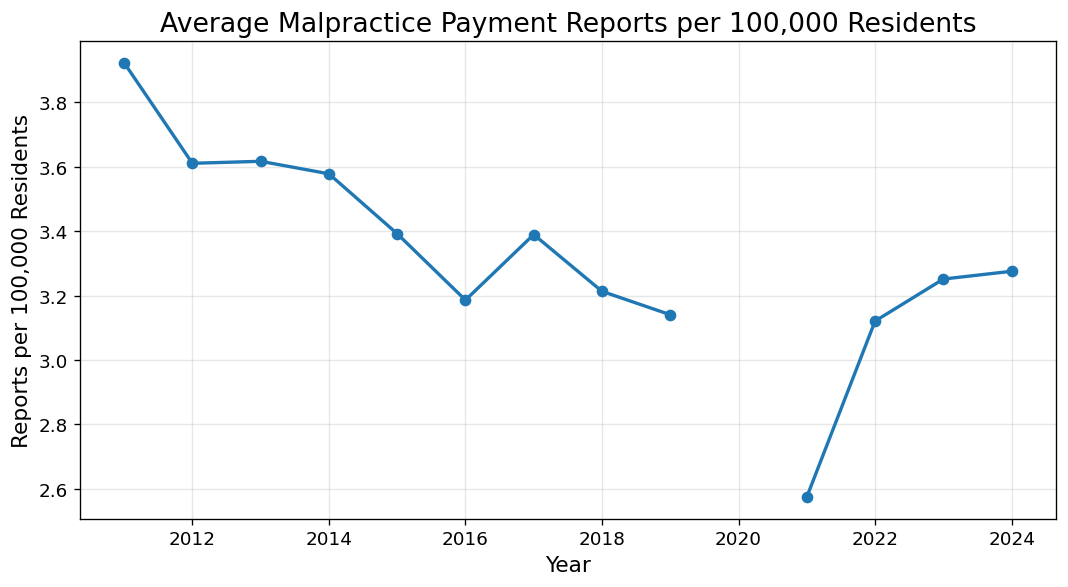

In [184]:
annual_reports = (
    master
    .groupby("year")["payment_reports_per_100k"]
    .mean()
)

plt.figure(figsize=(9,5))

plt.plot(
    annual_reports.index,
    annual_reports.values,
    marker="o",
    linewidth=2
)

plt.title("Average Malpractice Payment Reports per 100,000 Residents")

plt.xlabel("Year")
plt.ylabel("Reports per 100,000 Residents")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{FIGURE_FOLDER}/MASTER_Payment_Rate.png",
    bbox_inches="tight"
)

plt.show()

Figure 15 illustrates the average number of malpractice payment reports per 100,000 residents between 2011 and 2025. Adjusting report counts for population allows meaningful comparisons across states and over time. The overall trend remains relatively stable throughout most of the study period, with a temporary decline during 2020 and 2021 followed by recovery in subsequent years.

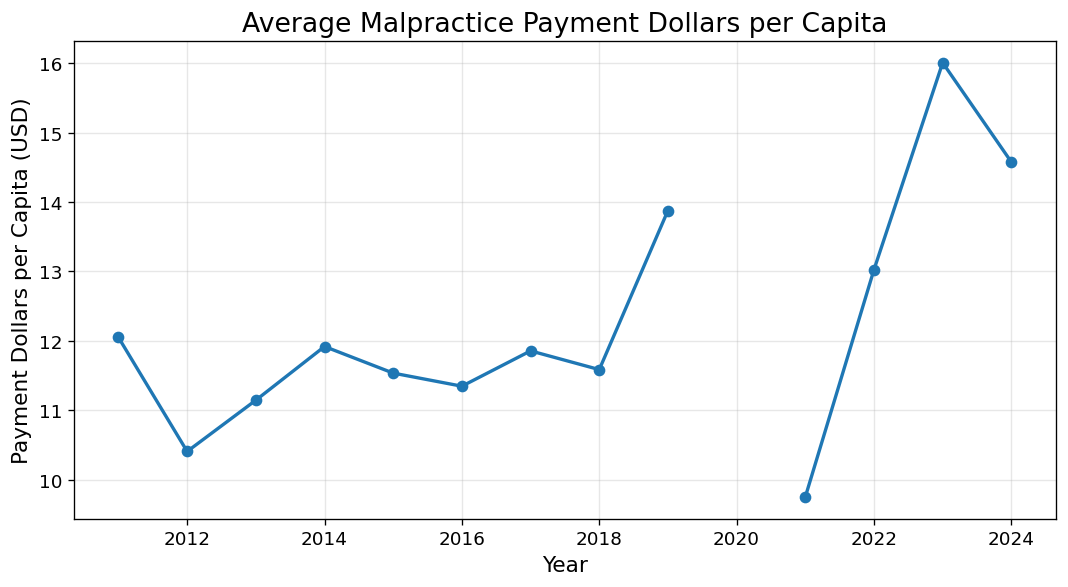

In [185]:
annual_payment = (
    master
    .groupby("year")["payment_dollars_per_capita"]
    .mean()
)

plt.figure(figsize=(9,5))

plt.plot(
    annual_payment.index,
    annual_payment.values,
    marker="o",
    linewidth=2
)

plt.title("Average Malpractice Payment Dollars per Capita")

plt.xlabel("Year")
plt.ylabel("Payment Dollars per Capita (USD)")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{FIGURE_FOLDER}/MASTER_Payment_Per_Capita.png",
    bbox_inches="tight"
)

plt.show()

Figure 16 presents annual malpractice payment dollars per capita. Population adjustment provides a standardized measure of malpractice-related financial burden that facilitates comparison across states of varying population sizes. Payment amounts generally increase throughout the study period despite short-term fluctuations.

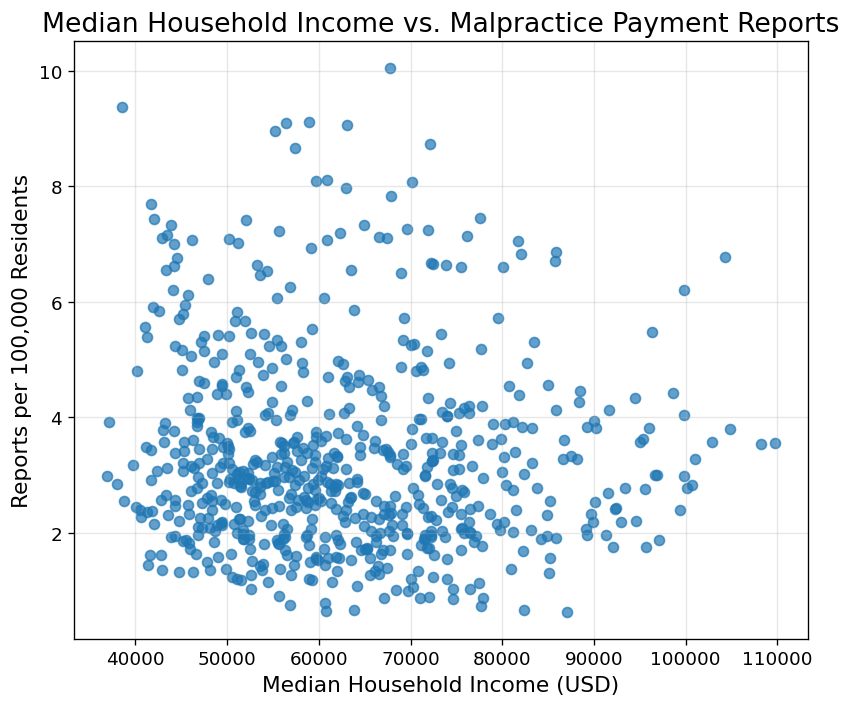

In [186]:
plt.figure(figsize=(7,6))

plt.scatter(
    master["median_household_income"],
    master["payment_reports_per_100k"],
    alpha=0.7
)

plt.title("Median Household Income vs. Malpractice Payment Reports")

plt.xlabel("Median Household Income (USD)")
plt.ylabel("Reports per 100,000 Residents")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{FIGURE_FOLDER}/MASTER_Income_vs_Reports.png",
    bbox_inches="tight"
)

plt.show()

Figure 17 examines the relationship between median household income and malpractice payment reports per 100,000 residents. The scatterplot provides an initial visual assessment of whether states with higher household incomes tend to experience different malpractice reporting frequencies than states with lower household incomes.

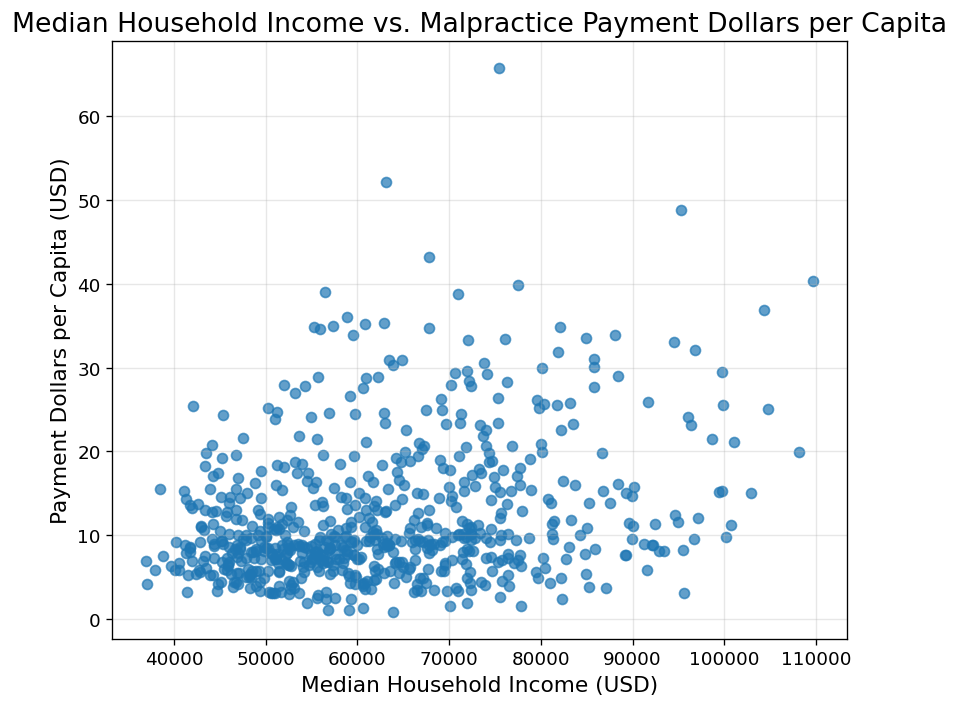

In [187]:
plt.figure(figsize=(7,6))

plt.scatter(
    master["median_household_income"],
    master["payment_dollars_per_capita"],
    alpha=0.7
)

plt.title("Median Household Income vs. Malpractice Payment Dollars per Capita")

plt.xlabel("Median Household Income (USD)")
plt.ylabel("Payment Dollars per Capita (USD)")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{FIGURE_FOLDER}/MASTER_Income_vs_Payments.png",
    bbox_inches="tight"
)

plt.show()

Figure 18 illustrates the relationship between median household income and malpractice payment dollars per capita. The figure provides a preliminary assessment of whether states with higher household incomes tend to exhibit greater malpractice-related financial burdens after adjusting for population.

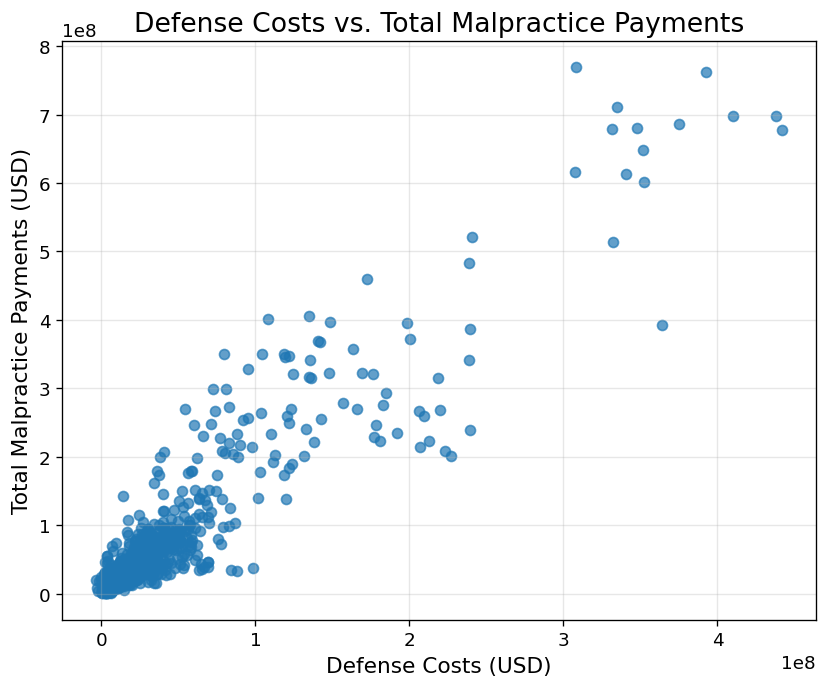

In [188]:
plt.figure(figsize=(7,6))

plt.scatter(
    master["defense_costs"],
    master["total_payments"],
    alpha=0.7
)

plt.title("Defense Costs vs. Total Malpractice Payments")

plt.xlabel("Defense Costs (USD)")
plt.ylabel("Total Malpractice Payments (USD)")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{FIGURE_FOLDER}/MASTER_Defense_vs_Payments.png",
    bbox_inches="tight"
)

plt.show()

Figure 19 compares insurer defense costs with total malpractice payment amounts across state-year observations. A positive association is evident, suggesting that states experiencing larger malpractice payment totals also tend to incur higher defense expenditures.

In [219]:
correlation_matrix = (
    master[
        [
            "payment_reports_per_100k",
            "payment_dollars_per_capita",
            "premiums_written",
            "losses",
            "defense_costs",
            "median_household_income",
            "poverty_rate",
            "education_rate"
        ]
    ]
    .corr()
    .round(3)
)

save_table(
    correlation_matrix,
    "Figures/Master_Correlation_Matrix.png"
)
correlation_matrix

,payment_reports_per_100k,payment_dollars_per_capita,premiums_written,losses,defense_costs,median_household_income,poverty_rate,education_rate
payment_reports_per_100k,1.000,0.694,0.434,0.463,0.433,-0.062,0.191,0.025
payment_dollars_per_capita,0.694,1.000,0.387,0.451,0.376,0.296,-0.127,0.319
premiums_written,0.434,0.387,1.000,0.957,0.968,0.167,0.017,0.173
losses,0.463,0.451,0.957,1.000,0.941,0.196,-0.024,0.196
defense_costs,0.433,0.376,0.968,0.941,1.000,0.125,0.045,0.135
median_household_income,-0.062,0.296,0.167,0.196,0.125,1.000,-0.724,0.803
poverty_rate,0.191,-0.127,0.017,-0.024,0.045,-0.724,1.000,-0.544
education_rate,0.025,0.319,0.173,0.196,0.135,0.803,-0.544,1.000


Table 5 presents Pearson correlation coefficients among the principal malpractice, insurer financial, and socioeconomic variables included in the merged state-year dataset. The matrix provides an initial assessment of linear relationships among the study variables and assists in identifying potentially important associations prior to formal statistical modeling.

In [191]:
missing_summary = (
    master
    .isna()
    .sum()
    .to_frame("Missing Values")
)

missing_summary

,Missing Values
state,0
year,0
payment_reports,0
total_payments,0
mean_payment,0
...,...
doctorate,102
state_fips,102
poverty_rate,102
bachelors_or_higher,102


A missing value assessment was performed following the integration of the NPDB, NAIC, ACS, and Population Estimates Program datasets. No unexpected missing values were identified following the data cleaning process. The only remaining missing values occur within the American Community Survey (ACS) socioeconomic variables for 2020 and 2025.

These missing observations are expected because the U.S. Census Bureau did not release standard ACS 1-Year estimates for 2020 due to data quality concerns associated with the COVID-19 pandemic, and 2025 ACS 1-Year estimates were unavailable at the time of this analysis. Population estimates for these years were obtained separately from the Census Population Estimates Program (PEP), allowing population-adjusted malpractice measures to be calculated across the entire 2011--2025 study period while preserving the availability of observed socioeconomic data.

In [192]:
print(f"Observations: {master.shape[0]}")
print(f"Variables: {master.shape[1]}")
print(f"States: {master['state'].nunique()}")
print(f"Years: {master['year'].min()}–{master['year'].max()}")

Observations: 766
Variables: 61
States: 51
Years: 2011–2025



The merged state-year dataset combines malpractice payment reports, insurer financial measures, annual population estimates, and state-level socioeconomic characteristics into a single analytical dataset. The dataset contains one observation for each state-year combination within the study period and includes financial, demographic, and socioeconomic variables used throughout the subsequent exploratory and statistical analyses.

The dataset overview confirms that all variables were imported successfully, assigned appropriate data types, and retained following the data integration process. Missing values are limited to the expected ACS socioeconomic variables for 2020 and 2025.

## Summary of Master Dataset Findings


The merged state-year dataset integrates malpractice payment activity, insurer financial measures, annual population estimates, and socioeconomic characteristics into a unified analytical framework. Population-adjusted malpractice measures facilitate meaningful comparisons across states and over time, while exploratory scatterplots identify observable associations between malpractice activity, insurer financial measures, and socioeconomic conditions. These exploratory findings provide the foundation for the formal statistical analyses presented in the subsequent sections of the study.